<a href="https://colab.research.google.com/github/Rinna-codes/Final-Milestone-AI-Implementation-Project/blob/main/final_implementaiton_zharinna.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#ReadME

**Project Overview**
This milestone project buils a movie plt genre generation using the pretrained model (facebook/opt-125m) on a cleaned IMDB movie datset. Given a movie's plot description, the model will generate the correct multi-lable in the following format:

Input:  Plot: [description] -> Genre:

Output: Comedy, Drama, Romance

There are 3 Systems Being Compared:
* Base Model: opt-125m with no fine tuning.
* Full SFT: All 125 million parameters are trained through Supervised Fine Tuning.
* LORA: Only a specifc number of parameters (294,912) are trained through Parameter-Efficient Fine Tuning (PEFT).

**Key Findings**: LORA dramatically outperforms the full fine tuning on the small dataset, which avoids a collapse that was discovered in full SFT.

**Environment & Setup Instructions**
1) Open notebook in Google CoLab with A GPU (T4 GPU) at the runtime type.
2) Upload the output_data.json file to the CoLab folder.
3) Install all the dependcies that are the first two cells at the top of the notebook. Only need to run them once to keep dependencies up to date.

**Run Training & Evaluation/Where to Produce the Demo**
Run ALL of the cells directly from top to bottom. See the "Table of Contents" for better navigation of the notebook.

Total Runtime is from 10 to 15 minutes on T4 GPU.

**Reproduce Plots and Tables**
* Learning Curves are generated and save in "results" folder under section "Learning + Loss Values Comparisons" cell .
* Comparison Tables are displayed under the section "Results Comparisons" cell, it uses pandas and shows the trainable parameters+percentage, validation and training loss, and generation quality across all three systems.
* Generation Output Tables are displayed when running the specific cells of "Baseline Model Generations", "Full Supervised Fine Tuning", and "LORA Supervised Fine Tuning".

**Where Outputs Are Saved**
* Learning Curve: results folder
* Full SFT Check points: movie_genre_outputs/full_ft
* LORA Training checkpoints: movie_genre_outputs/LORA_sft

**Hardware Assumptions & Resource Limitations**
* GPU Required: This notebook requires that the runtime is GPU, using CPU would result in the runtime becing extremely slow and is not recommanded.
* Recommanded Hardware: Google CoLab T4 GPU
* RAM: 12GB RAM is enough
* Limitations: Full SFT experiences a collapse due to the dataset size, LORA is the recommanded system to reprimand that.

# Run coding cell directly below ONLY ONCE for each work session

In [ ]:
%pip -q install -U trl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 751.0/751.0 kB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 529.0/529.0 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.9/48.9 MB 19.0 MB/s eta 0:00:00


In [ ]:
%pip install --upgrade torchao

# Imports Needed

In [ ]:
import json
import os
import random
import torch
import gc
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score
from datasets import Dataset, DatasetDict
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import LoraConfig, TaskType,get_peft_model
from trl import SFTTrainer, SFTConfig

import tiktoken

# 1) Data Loading & Exploration Pipeline


### Preparing the dataset

What happens:
* Open and load the JSON
* Loop through entries
* Handle the description
* Strip and join the genres
* Build the f-string
* Append to a list
* Print a few examples to verify

In [ ]:
with open('output_data.json', 'r', encoding='utf-8') as json_file:
  list_of_movies_and_genres = json.load(json_file) # load the output_data json file

formatted_entries = [] # where entries will be appened onto

for movie in list_of_movies_and_genres: # loop through each movie + their genres
  movie_descriptions = movie['Description'].strip() # extract only the descriptions

  clean_genres = [g.strip() for g in movie['Genre']] # extract only the genres and strip of leading spaces
  movie_genres = ", ".join(clean_genres)

  entries = { # follows the alpaca prompts
      "prompt" : f"Plot: {movie_descriptions} -> Genre:",
      "completion" : f"{movie_genres}"
  }

  formatted_entries.append(entries)

# print to see examples
for examples in formatted_entries[:5]:
  print(examples, '\n')

# santity check, data loaded correctly
print(f"Amount of Entries: {len(formatted_entries)}")


{'prompt': 'Plot: Solène, a 40-year-old single mom, begins an unexpected romance with 24-year-old Hayes Campbell, the lead singer of August Moon, the hottest boy band on the planet. -> Genre:', 'completion': 'Comedy, Drama, Romance'} 

{'prompt': "Plot: Many years after the reign of Caesar, a young ape goes on a journey that will lead him to question everything he's been taught about the past and make choices that will define a future for apes and humans alike. -> Genre:", 'completion': 'Action, Adventure, Sci-Fi'} 

{'prompt': "Plot: In 1963 Michigan, business rivals Kellogg's and Post compete to create a cake that could change breakfast forever. -> Genre:", 'completion': 'Biography, Comedy, History'} 

{'prompt': "Plot: A down-and-out stuntman must find the missing star of his ex-girlfriend's blockbuster film. -> Genre:", 'completion': 'Action, Comedy, Drama'} 

{'prompt': "Plot: Tashi, a former tennis prodigy turned coach, turned her husband into a champion. But to overcome a losing

In [ ]:
# coverting to HuggingFace object for clearner code
dataset = Dataset.from_list(formatted_entries)

# reproducibility
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

# split the data into training, validation, testing
take_training_data = dataset.train_test_split(test_size=0.20, seed=SEED)
take_validation_data = take_training_data['test'].train_test_split(test_size=0.50, seed=SEED)

new_split_dataset = DatasetDict({
    "training_data": take_training_data["train"],
    "validation_data": take_validation_data["train"],
    "testing_data": take_validation_data["test"],
})

print(new_split_dataset)

DatasetDict({
    training_data: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 240
    })
    validation_data: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 30
    })
    testing_data: Dataset({
        features: ['prompt', 'completion'],
        num_rows: 30
    })
})


# 2) Baseline Model Generations
* This is to see what the baseline model generates before any sort of fine tuning is established, or after full fine tuning, and after implementing LORA

In [ ]:
model_id = "facebook/opt-125m" # Define the model id for tokenizer

tokenizer = AutoTokenizer.from_pretrained(model_id)

# grab 5 prompts for the baseline model from the testing data of the dataset
Prompt_Suite = [new_split_dataset['testing_data'][i]['prompt'] for i in range(min(6, len(new_split_dataset['testing_data'])))]
reference_completion = [new_split_dataset['testing_data'][i]["completion"] for i in range(min(6, len(new_split_dataset['testing_data']))) ]

def generate_responses(model, tokenizer, prompts, max_new_tokens=30):
    """Generate some outputs for five prompts"""

    model.eval()
    outputs = []
    device = next(model.parameters()).device
    for prompt in prompts:
        inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=256).to(device)
        with torch.no_grad():
            gen = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )
        decoded = tokenizer.decode(gen[0], skip_special_tokens=True)
        outputs.append(decoded[len(prompt):].strip() if decoded.startswith(prompt) else decoded.strip())
    return outputs

# create baseline model for comparison evaluations
baseline_model = AutoModelForCausalLM.from_pretrained(model_id)
baseline_model.resize_token_embeddings(len(tokenizer))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.decoder.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Embedding(50265, 768, padding_idx=1)

In [ ]:
# generate responses from the five prompts
baseline_model_outputs = generate_responses(baseline_model, tokenizer, Prompt_Suite)

display(pd.DataFrame({
    "prompt": Prompt_Suite,
    "base_output": baseline_model_outputs,
    "reference_completion": reference_completion,
}))

,prompt,base_output,reference_completion
0,"Plot: In a time of conflict, a group of unlike...","Action, Sci-Fi, Fantasy, Horror, Drama, Drama,...","Action, Adventure, Sci-Fi"
1,"Plot: Cecilia, a woman of devout faith, is war...","Romance, Drama, Drama, Drama, Drama, Drama, Dr...",Horror
2,Plot: With dreams of opening a shop in a city ...,"Chocolate, Fantasy, Horror, Horror, Horror, Ho...","Adventure, Comedy, Family"
3,Plot: Lonely residents of a tornado-stricken O...,"Horror, Sci-Fi, Fantasy, Romance, Romance, Rom...","Comedy, Drama"
4,"Plot: In the dead of a Wyoming winter, a bount...","Horror, Fantasy, Sci-Fi, Fantasy, Sci-Fi, Fant...","Crime, Drama, Mystery"
5,Plot: When soulmates Eric and Shelly are bruta...,"Drama, Romance, Action, Action, Action, Action...","Action, Crime, Fantasy"


# 3) Full Supervised Fine Tuning (SFT)

In [ ]:
# helper functions (7, the icon 7 tannies!!)
def count_trainable_params(model):
    """Return trainable params, total params, and trainable percentage."""
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    pct = 100 * trainable / total
    return trainable, total, pct

def summarize_trainable_params(model, label="model"):
    """Print and return a compact parameter summary for easy comparison."""
    trainable, total, pct = count_trainable_params(model)
    print(f"{label}: trainable={trainable:,} | total={total:,} | trainable%={pct:.2f}")
    return {
        "trainable_params": trainable,
        "total_params": total,
        "trainable_pct": pct,
    }

def history_df(trainer):
    """Turn a Trainer/SFTTrainer log history into a DataFrame."""
    return pd.DataFrame(trainer.state.log_history)

def epoch_history_table(trainer, columns=None):
    """Show only the most useful training/eval columns."""
    hist = history_df(trainer)
    if hist.empty:
        return hist
    if columns is None:
        columns = [
            "epoch", "loss", "eval_loss", "eval_accuracy", "eval_macro_f1",
            "learning_rate", "grad_norm", "mean_token_accuracy"
        ]
    cols = [c for c in columns if c in hist.columns]
    if not cols:
        return hist
    metric_cols = [c for c in cols if c != "epoch"]
    table = hist.dropna(subset=metric_cols, how="all").copy()
    if table.empty:
        table = hist.copy()
    return table[cols].reset_index(drop=True)

def last_logged_metrics(trainer, prefix="eval_"):
    """Grab the last logged evaluation metrics from the trainer history."""
    hist = history_df(trainer)
    if hist.empty:
        return {}
    cols = [c for c in hist.columns if c.startswith(prefix)]
    if not cols:
        return {}
    rows = hist.dropna(subset=cols, how="all")
    if rows.empty:
        return {}
    last = rows.iloc[-1]
    return {c: last[c] for c in cols if pd.notna(last[c])}

def remove_notebook_progress_callback(trainer):
    """Avoid notebook callback issues before calling predict()."""
    try:
        from transformers.utils.notebook import NotebookProgressCallback
        trainer.remove_callback(NotebookProgressCallback)
    except Exception:
        pass

def cleanup(*objs):
    """Free memory between large runs."""
    for obj in objs:
        del obj
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()



In [ ]:
# create full supervise fine tuning model for comparison evaluations
full_SFT_model = AutoModelForCausalLM.from_pretrained(model_id)
full_SFT_model.resize_token_embeddings(len(tokenizer))

sft_model_outputs = {}

# output the full supervised fine tuning model
sft_model_outputs["full_ft"] = summarize_trainable_params(full_SFT_model, label="Instruction SFT / Full FT")

full_SFT_args = SFTConfig(
    output_dir="movie_genre_outputs/full_ft",
    num_train_epochs=6,
    learning_rate=2e-5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    logging_steps=20,
    logging_strategy="steps",
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    disable_tqdm=False,
    max_length=256,
    completion_only_loss=True,
    gradient_checkpointing=False,
    seed=42,
)

full_SFT_trainer = SFTTrainer(
    model=full_SFT_model,
    args=full_SFT_args,
    train_dataset=new_split_dataset["training_data"],
    eval_dataset=new_split_dataset["validation_data"],
    processing_class=tokenizer,
)

full_SFT_trainer_output = full_SFT_trainer.train()
remove_notebook_progress_callback(full_SFT_trainer)

full_SFT_eval = last_logged_metrics(full_SFT_trainer)
sft_model_outputs["full_ft"].update({
    "train_runtime": full_SFT_trainer_output.metrics.get("train_runtime"),
    **full_SFT_eval,
})

display(epoch_history_table(full_SFT_trainer, ["epoch", "loss", "eval_loss", "mean_token_accuracy", "learning_rate", "grad_norm"]))
display(pd.DataFrame([sft_model_outputs["full_ft"]])[[
    "trainable_params", "total_params", "trainable_pct", "train_runtime", "eval_loss"
]].round(4))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.decoder.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Instruction SFT / Full FT: trainable=125,233,920 | total=125,233,920 | trainable%=100.00


Adding EOS to train dataset:   0%|          | 0/240 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/240 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

Epoch,Training Loss,Validation Loss
1,882.097168,1190.066406
2,1136.395703,1181.260620
3,915.480762,566.496460
4,739.771924,715.700623
5,530.735254,459.451477
6,297.668042,286.705292


,epoch,loss,eval_loss,mean_token_accuracy,learning_rate,grad_norm
0,0.666667,882.097168,NaN,0.073560,1.788889e-05,242.125
1,1.000000,NaN,1190.066406,NaN,NaN,NaN
2,1.333333,1124.140332,NaN,0.014316,1.566667e-05,137.500
3,2.000000,1136.395703,NaN,0.029440,1.344444e-05,865.500
4,2.000000,NaN,1181.260620,NaN,NaN,NaN
5,2.666667,915.480762,NaN,0.027146,1.122222e-05,1058.000
6,3.000000,NaN,566.496460,NaN,NaN,NaN
7,3.333333,734.038770,NaN,0.022229,9.000000e-06,1784.000
8,4.000000,739.771924,NaN,0.004670,6.777778e-06,444.000
9,4.000000,NaN,715.700623,NaN,NaN,NaN


,trainable_params,total_params,trainable_pct,train_runtime,eval_loss
0,125233920,125233920,100.0,59.2751,286.7053


In [ ]:
# generate responses for Full Supervised Training from the five prompts
full_SFT_outputs = generate_responses(full_SFT_model, tokenizer, Prompt_Suite)

display(pd.DataFrame({
    "prompt": Prompt_Suite,
    "full_model output": full_SFT_outputs,
    "reference_completion": reference_completion,
}))

,prompt,full_model output,reference_completion
0,"Plot: In a time of conflict, a group of unlike...",Family Family Family Family Family Family Fami...,"Action, Adventure, Sci-Fi"
1,"Plot: Cecilia, a woman of devout faith, is war...",Family Family Family Family Family Family Fami...,Horror
2,Plot: With dreams of opening a shop in a city ...,Family Family Family Family Family Family Fami...,"Adventure, Comedy, Family"
3,Plot: Lonely residents of a tornado-stricken O...,Family Family Family Family Family Family Fami...,"Comedy, Drama"
4,"Plot: In the dead of a Wyoming winter, a bount...",Family Family Family Family Family Family Fami...,"Crime, Drama, Mystery"
5,Plot: When soulmates Eric and Shelly are bruta...,Family Family Family Family Family Family Fami...,"Action, Crime, Fantasy"


# 4) LORA Supervised Fine Tuning (SFT)

In [ ]:
sft_LORA_model = AutoModelForCausalLM.from_pretrained(model_id)
sft_LORA_model.resize_token_embeddings(len(tokenizer))

sft_LORA_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=8,
    lora_alpha=16,
    lora_dropout=0.10,
    target_modules=["q_proj", "v_proj"],
)

sft_LORA_args = SFTConfig(
    output_dir="movie_genre_outputs/LORA_sft",
    num_train_epochs=5,
    learning_rate=1e-4,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=4,
    logging_steps=20,
    logging_strategy="steps",
    eval_strategy="epoch",
    save_strategy="no",
    report_to="none",
    disable_tqdm=False,
    max_length=256,
    completion_only_loss=True,
    gradient_checkpointing=False,
    seed=42,
)

# Let SFTTrainer wrap the model with LoRA through peft_config.
sft_LORA_trainer = SFTTrainer(
    model=sft_LORA_model,
    args=sft_LORA_args,
    train_dataset=new_split_dataset["training_data"],
    eval_dataset=new_split_dataset["validation_data"],
    processing_class=tokenizer,
    peft_config=sft_LORA_config,
)

# Recompute params on the actual wrapped model used by the trainer.
sft_model_outputs["lora"] = summarize_trainable_params(sft_LORA_trainer.model, label="LoRA")

sft_LORA_train_output = sft_LORA_trainer.train()
remove_notebook_progress_callback(sft_LORA_trainer)

sft_LORA_eval = last_logged_metrics(sft_LORA_trainer)
sft_model_outputs["lora"].update({
    "train_runtime": sft_LORA_train_output.metrics.get("train_runtime"),
    **sft_LORA_eval,
})

display(epoch_history_table(sft_LORA_trainer, ["epoch", "loss", "eval_loss", "mean_token_accuracy", "learning_rate", "grad_norm"]))
display(pd.DataFrame([sft_model_outputs["lora"]])[[
    "trainable_params", "total_params", "trainable_pct", "train_runtime", "eval_loss"
]].round(4))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.decoder.embed_tokens.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


Adding EOS to train dataset:   0%|          | 0/240 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/240 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

LoRA: trainable=294,912 | total=125,528,832 | trainable%=0.23


Epoch,Training Loss,Validation Loss
1,2.797210,1.608497
2,1.444655,1.276533
3,1.333805,1.165583
4,1.179647,1.119217
5,1.167642,1.108363


,epoch,loss,eval_loss,mean_token_accuracy,learning_rate,grad_norm
0,0.666667,2.797210,NaN,0.426263,0.000087,6.234342
1,1.000000,NaN,1.608497,NaN,NaN,NaN
2,1.333333,1.816973,NaN,0.550701,0.000074,5.042843
3,2.000000,1.444655,NaN,0.628612,0.000061,5.431504
4,2.000000,NaN,1.276533,NaN,NaN,NaN
5,2.666667,1.333805,NaN,0.647229,0.000047,4.181112
6,3.000000,NaN,1.165583,NaN,NaN,NaN
7,3.333333,1.211536,NaN,0.657886,0.000034,5.903909
8,4.000000,1.179647,NaN,0.669699,0.000021,6.917684
9,4.000000,NaN,1.119217,NaN,NaN,NaN


,trainable_params,total_params,trainable_pct,train_runtime,eval_loss
0,294912,125528832,0.2349,52.5001,1.1084


In [ ]:
# generate responses for LORA from the five prompts
LORA_sft_outputs = generate_responses(sft_LORA_model,tokenizer, Prompt_Suite)

display(pd.DataFrame({
    "prompt": Prompt_Suite,
    "lora_model outputs": LORA_sft_outputs,
    "reference_completion": reference_completion,
}))

,prompt,lora_model outputs,reference_completion
0,"Plot: In a time of conflict, a group of unlike...","Action, Adventure, Sci-Fi","Action, Adventure, Sci-Fi"
1,"Plot: Cecilia, a woman of devout faith, is war...","Action, Adventure, Drama",Horror
2,Plot: With dreams of opening a shop in a city ...,"Comedy, Adventure, Thriller","Adventure, Comedy, Family"
3,Plot: Lonely residents of a tornado-stricken O...,"Action, Adventure, Thriller","Comedy, Drama"
4,"Plot: In the dead of a Wyoming winter, a bount...","Action, Adventure, Thriller","Crime, Drama, Mystery"
5,Plot: When soulmates Eric and Shelly are bruta...,"Action, Adventure, Drama","Action, Crime, Fantasy"


# 5) Results Comparisons

In [ ]:
# Comparison for the metrics of both
rows = [
    {
        "task": "instruction_following",
        "method": "baseline",
        "trainable_params": "N/A",
        "trainable_pct": "100%",
        "runtime_or_loss": "N/A",
        "primary_metric_name": "generation_quality",
    },
    {
        "task": "instruction_following",
        "method": "full_sft",
        "trainable_params": sft_model_outputs["full_ft"]["trainable_params"],
        "trainable_pct": sft_model_outputs["full_ft"]["trainable_pct"],
        "runtime_or_loss": sft_model_outputs["full_ft"].get("eval_loss"),
        "primary_metric_name": "generation_quality",
    },
    {
        "task": "instruction_following",
        "method": "lora",
        "trainable_params": sft_model_outputs["lora"]["trainable_params"],
        "trainable_pct": sft_model_outputs["lora"]["trainable_pct"],
        "runtime_or_loss": sft_model_outputs["lora"].get("eval_loss"),
        "primary_metric_name": "generation_quality",
    }
]

final_compare = pd.DataFrame(rows)
final_compare[["trainable_pct", "runtime_or_loss"]] = final_compare[["trainable_pct", "runtime_or_loss"]].round(4)
display(final_compare)

,task,method,trainable_params,trainable_pct,runtime_or_loss,primary_metric_name
0,instruction_following,baseline,N/A,100%,N/A,generation_quality
1,instruction_following,full_sft,125233920,100.0,286.705292,generation_quality
2,instruction_following,lora,294912,0.234936,1.108363,generation_quality


In [ ]:
display(pd.DataFrame({
    "prompt": Prompt_Suite,
    "Base" : baseline_model_outputs,
    "Full" : full_SFT_outputs,
    "LORA": LORA_sft_outputs,
    "reference_completion": reference_completion,
}))

,prompt,Base,Full,LORA,reference_completion
0,"Plot: In a time of conflict, a group of unlike...","Action, Sci-Fi, Fantasy, Horror, Drama, Drama,...",Family Family Family Family Family Family Fami...,"Action, Adventure, Sci-Fi","Action, Adventure, Sci-Fi"
1,"Plot: Cecilia, a woman of devout faith, is war...","Romance, Drama, Drama, Drama, Drama, Drama, Dr...",Family Family Family Family Family Family Fami...,"Action, Adventure, Drama",Horror
2,Plot: With dreams of opening a shop in a city ...,"Chocolate, Fantasy, Horror, Horror, Horror, Ho...",Family Family Family Family Family Family Fami...,"Comedy, Adventure, Thriller","Adventure, Comedy, Family"
3,Plot: Lonely residents of a tornado-stricken O...,"Horror, Sci-Fi, Fantasy, Romance, Romance, Rom...",Family Family Family Family Family Family Fami...,"Action, Adventure, Thriller","Comedy, Drama"
4,"Plot: In the dead of a Wyoming winter, a bount...","Horror, Fantasy, Sci-Fi, Fantasy, Sci-Fi, Fant...",Family Family Family Family Family Family Fami...,"Action, Adventure, Thriller","Crime, Drama, Mystery"
5,Plot: When soulmates Eric and Shelly are bruta...,"Drama, Romance, Action, Action, Action, Action...",Family Family Family Family Family Family Fami...,"Action, Adventure, Drama","Action, Crime, Fantasy"


# 6) Learning + Loss Values Comparison Plots

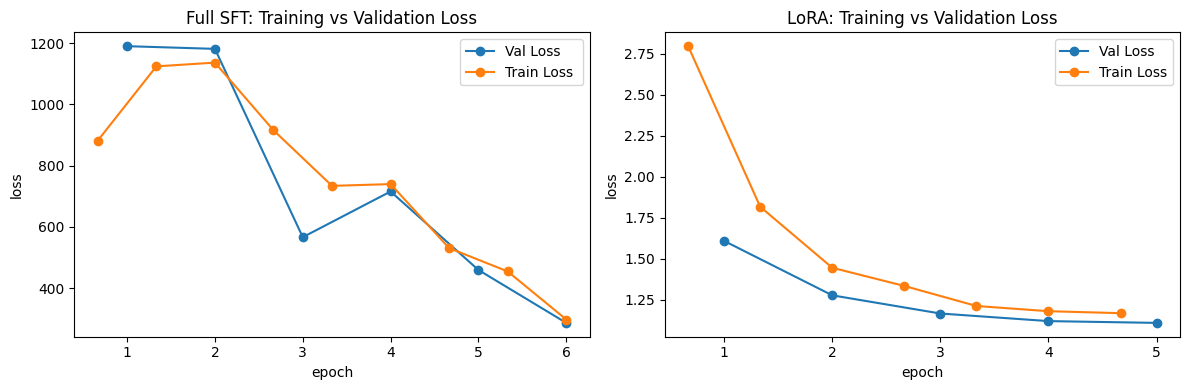

In [ ]:
SFT_full_history = history_df(full_SFT_trainer)
lora_history = history_df(sft_LORA_trainer)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

full_eval = SFT_full_history.dropna(subset=["eval_loss"]) if "eval_loss" in SFT_full_history else pd.DataFrame()
full_train = SFT_full_history.dropna(subset=["loss"])
lora_eval = lora_history.dropna(subset=["eval_loss"]) if "eval_loss" in lora_history else pd.DataFrame()
lora_train = lora_history.dropna(subset=["loss"])

# code for the Supervised Fine Tuning
if not full_eval.empty:
    axes[0].plot(full_eval["epoch"], full_eval["eval_loss"], marker="o", label="Val Loss")
    axes[0].plot( full_train["epoch"], full_train["loss"], marker="o", label="Train Loss ")
axes[0].set_title("Full SFT: Training vs Validation Loss")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss")
axes[0].legend()

# code for the lora fine tuning
if not lora_eval.empty:
    axes[1].plot(lora_eval["epoch"], lora_eval["eval_loss"], marker="o", label="Val Loss")
    axes[1].plot(lora_train["epoch"], lora_train["loss"], marker="o", label="Train Loss")
axes[1].set_title("LoRA: Training vs Validation Loss")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("loss")
axes[1].legend()

plt.tight_layout()
os.makedirs("results", exist_ok=True)
plt.savefig("results/learning_curves.png", dpi=150, bbox_inches='tight')
plt.show()

# Error Analysis Cell

## Failure Case 1: Horror Movie Prediction

**Plot Description**: "Cecilia, a woman of devout faith, is warmly welcomed to the picture-perfect Italian countryside where she is offered a new role at an illustrious convent. But it becomes clear to Cecilia that her new home harbors dark and horrifying secrets."

**What LORA Predicted**: Genres: Action, Adventure, Drama

**Reference**: Horror

**Why It Failed**:System probably latched onto words like "warmly welcomed" as the the signal of what genre the description was labeling it as at the start of the plot description only. This is further true with how the the words "dark and horrifying secrets" appear towards the end of the description.

## Failure Case 2: Family Movie Prediction

**Plot Description**: "With dreams of opening a shop in a city renowned for its chocolate, a young and poor Willy Wonka discovers that the industry is run by a cartel of greedy chocolatiers."

**What LORA Predicted**: Genres: Comedy, Adventure, Thriller

**Reference**: Adventure, Comedy, Family

**Why It Failed**:Given the description has a wording of "cartel of greedy chocolatiers, the system probably latched onto this in association to "Thriller". It should also be stated that the "Family" genre label is not exactly explicit in its lingusitic signals for the plot summary itself. It's a metadata label that is hard to distinguish from a the plot's lanugage alone.

## Failure Case 3: Comedy, Drama Movie

**Plot Description**: "Lonely residents of a tornado-stricken Ohio town wander the deserted landscape trying to fulfill their boring, nihilistic lives."

**What LORA Predicted**: Genres: Action, Adventure, Thriller

**Reference**: Comedy, Drama

**Why It Failed**:Same case for failure case 1, the system latched onto words of the likes of "tornado-stricken", "deserted landscape", and "nihilistic lives" that probably prompted the system to give "Thriller" as a a genre for it. They are rather dark and intense words that the system misread the tone of the plot description. Being able to label comedy and drama requires understanding subtle human context, not just surface level drastic language.

The model is showing a strong bias to three specific genre label: "Action", "Adventure", and "Thriller". The system is likely making these over-predicting actions towards these genres as it probablt dominates the dataset, meaning it appears for several genre labels for severl movie plot descriptions.